# Metro de la CDMX: matriz de adyacencia y Dijkstra

**Lógica Matemática y Matemáticas Discretas**

Representamos las 12 líneas del Metro como un grafo no dirigido. Construimos su matriz de adyacencia e implementamos Dijkstra con una cola de prioridad para encontrar una ruta mínima. Al final contrastamos los resultados con NetworkX.

## 1. Dependencias y datos

Ejecutar las celdas en orden desde la carpeta del repositorio. Se necesitan `networkx`, `matplotlib`, `numpy` y un entorno Jupyter. Los recorridos se importan de `datos.py`, el mismo archivo utilizado por el programa principal.

In [1]:
import heapq
import math
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datos import LINEAS, COLORES

## 2. Construcción del grafo

En **G = (V, E)**, cada vértice es una estación y cada arista une dos estaciones consecutivas de una línea. Las correspondencias comparten un solo vértice. Una conexión tiene peso **1**, equivalente a recorrer un tramo; no representa minutos ni kilómetros. Los transbordos no añaden costo.

Utilizamos el atributo `weight`, como en los ejemplos de clase. La red es estructural: no incluye cierres temporales ni ampliaciones en construcción.

In [2]:
G = nx.Graph()
for linea, estaciones in LINEAS.items():
    for estacion in estaciones:
        if estacion not in G:
            G.add_node(estacion, lineas=[])
        G.nodes[estacion]['lineas'].append(linea)
    for u, v in zip(estaciones, estaciones[1:]):
        G.add_edge(u, v, weight=1, linea=linea)

print('Líneas:', len(LINEAS))
print('Estaciones contadas por línea:', sum(len(e) for e in LINEAS.values()))
print('Vértices únicos:', G.number_of_nodes())
print('Aristas:', G.number_of_edges())
print('Componentes conexas:', nx.number_connected_components(G))
print('Vecinos de Tacubaya:', list(G.neighbors('Tacubaya')))
print('Grado de Tacubaya:', G.degree('Tacubaya'))

Líneas: 12
Estaciones contadas por línea: 195
Vértices únicos: 163
Aristas: 183
Componentes conexas: 1
Vecinos de Tacubaya: ['Observatorio', 'Juanacatlán', 'Constituyentes', 'San Pedro de los Pinos', 'Patriotismo']
Grado de Tacubaya: 5


## 3. Matriz de adyacencia

Fijamos un orden de estaciones para identificar las filas y columnas. La entrada **A[i, j]** vale 1 si las estaciones están conectadas y 0 si no lo están.

La matriz completa tiene **163 × 163** entradas. Es simétrica porque el grafo no es dirigido, su diagonal es cero porque no hay lazos y la suma de cada fila es el grado del vértice. Mostramos un bloque pequeño y un mapa de toda la matriz.

Dimensión: (163, 163)
Simétrica: True
Diagonal nula: True
Grados coinciden: True
Aristas a partir de A: 183


| Estación | Observatorio | Tacubaya | Juanacatlán | San Pedro de los Pinos | Mixcoac |
| --- | --- | --- | --- | --- | --- |
| Observatorio | 0 | 1 | 0 | 0 | 0 |
| Tacubaya | 1 | 0 | 1 | 1 | 0 |
| Juanacatlán | 0 | 1 | 0 | 0 | 0 |
| San Pedro de los Pinos | 0 | 1 | 0 | 0 | 0 |
| Mixcoac | 0 | 0 | 0 | 0 | 0 |


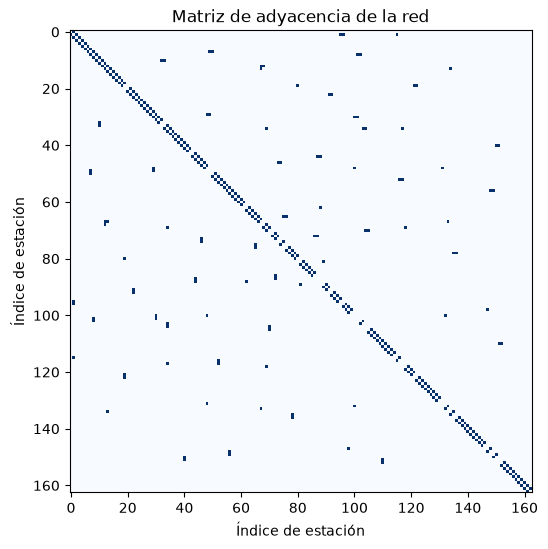

In [3]:
nodos = list(G.nodes())
indice = {nodo: i for i, nodo in enumerate(nodos)}
A = nx.to_numpy_array(G, nodelist=nodos, weight=None, dtype=int)

print('Dimensión:', A.shape)
print('Simétrica:', np.array_equal(A, A.T))
print('Diagonal nula:', np.all(np.diag(A) == 0))
print('Grados coinciden:', np.array_equal(A.sum(axis=1), [G.degree(n) for n in nodos]))
print('Aristas a partir de A:', int(A.sum() // 2))

seleccion = ['Observatorio', 'Tacubaya', 'Juanacatlán', 'San Pedro de los Pinos', 'Mixcoac']
indices = [indice[n] for n in seleccion]
bloque = A[np.ix_(indices, indices)]
tabla = '| Estación | ' + ' | '.join(seleccion) + ' |\n'
tabla += '| --- | ' + ' | '.join(['---'] * len(seleccion)) + ' |\n'
for nombre, fila in zip(seleccion, bloque):
    tabla += '| ' + nombre + ' | ' + ' | '.join(map(str, fila)) + ' |\n'
display(Markdown(tabla))

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(A, cmap='Blues', interpolation='nearest', vmin=0, vmax=1)
ax.set(title='Matriz de adyacencia de la red', xlabel='Índice de estación', ylabel='Índice de estación')
plt.show()

El bloque es una selección de filas y columnas de la matriz completa. Por ejemplo, Observatorio se conecta con Tacubaya. Mixcoac aparece con ceros en este bloque porque sus vecinos inmediatos no están en la selección; no es una estación aislada.

## 4. Lista de adyacencia

Para Dijkstra almacenamos cada estación con una lista de pares `(vecino, peso)`. La matriz requiere O(|V|²) espacio, mientras que esta lista requiere O(|V| + |E|), apropiado para una red con pocas conexiones por estación.

In [4]:
grafo = {
    u: [(v, datos['weight']) for v, datos in G[u].items()]
    for u in G
}
for u in ['Observatorio', 'Tacubaya', 'Mixcoac']:
    print(u, '->', grafo[u])

Observatorio -> [('Tacubaya', 1)]
Tacubaya -> [('Observatorio', 1), ('Juanacatlán', 1), ('Constituyentes', 1), ('San Pedro de los Pinos', 1), ('Patriotismo', 1)]
Mixcoac -> [('San Antonio', 1), ('Barranca del Muerto', 1), ('Insurgentes Sur', 1)]


## 5. Dijkstra paso a paso

1. Asignar distancia 0 al origen e infinito a las demás estaciones.
2. Extraer de la cola la estación con menor distancia tentativa.
3. Si ya fue visitada, descartar esa entrada. En caso contrario, finalizarla.
4. **Relajar** sus aristas: si pasar por ella mejora una distancia, actualizarla y guardar el predecesor.
5. Repetir hasta llegar al destino o vaciar la cola. Reconstruir el camino siguiendo los predecesores.

Dijkstra requiere pesos no negativos. Con un heap binario, esta implementación tiene complejidad O((|V| + |E|) log |V|) para este grafo simple. Guardamos las primeras extracciones para observar el avance del algoritmo.

In [5]:
def dijkstra(grafo, origen, destino):
    if origen not in grafo or destino not in grafo:
        raise ValueError('El origen y el destino deben existir en el grafo.')
    if any(peso < 0 for vecinos in grafo.values() for _, peso in vecinos):
        raise ValueError('Dijkstra requiere pesos no negativos.')

    distancias = {nodo: math.inf for nodo in grafo}
    anteriores = {nodo: None for nodo in grafo}
    distancias[origen] = 0
    visitados = set()
    cola = [(0, origen)]
    pasos = []

    while cola:
        distancia, u = heapq.heappop(cola)
        if u in visitados:
            continue
        visitados.add(u)
        pasos.append((u, distancia))
        if u == destino:
            break
        for v, peso in grafo[u]:
            if v in visitados:
                continue
            nueva_distancia = distancia + peso
            if nueva_distancia < distancias[v]:
                distancias[v] = nueva_distancia
                anteriores[v] = u
                heapq.heappush(cola, (nueva_distancia, v))

    if distancias[destino] == math.inf:
        return math.inf, [], pasos
    camino = []
    actual = destino
    while actual is not None:
        camino.append(actual)
        actual = anteriores[actual]
    return distancias[destino], camino[::-1], pasos

## 6. Aplicación al Metro

Buscamos un camino de **Observatorio a Universidad**. Se pueden cambiar las dos variables por otros nombres de `datos.py`. El algoritmo minimiza tramos, sin priorizar el menor número de transbordos. Si hay varios caminos de igual costo, puede devolver uno distinto al programa principal.

In [6]:
origen = 'Observatorio'
destino = 'Universidad'
costo, camino, pasos = dijkstra(grafo, origen, destino)
print('Camino:', ' -> '.join(camino))
print('Costo mínimo:', costo, 'tramos')
print('Estaciones visitadas en el camino:', len(camino))
print('Estaciones finalizadas durante la búsqueda:', len(pasos))

lineas_ruta = [G[u][v]['linea'] for u, v in zip(camino, camino[1:])]
transbordos = [camino[i] for i in range(1, len(lineas_ruta))
               if lineas_ruta[i] != lineas_ruta[i - 1]]
print('Transbordos:', len(transbordos), transbordos)
print('Primeras 10 estaciones finalizadas:')
for numero, (estacion, distancia) in enumerate(pasos[:10], start=1):
    print(f'{numero:2}. {estacion}: {distancia}')

Camino: Observatorio -> Tacubaya -> San Pedro de los Pinos -> San Antonio -> Mixcoac -> Insurgentes Sur -> Hospital 20 de Noviembre -> Zapata -> Coyoacán -> Viveros/Derechos Humanos -> Miguel Ángel de Quevedo -> Copilco -> Universidad
Costo mínimo: 12 tramos
Estaciones visitadas en el camino: 13
Estaciones finalizadas durante la búsqueda: 103
Transbordos: 3 ['Tacubaya', 'Mixcoac', 'Zapata']
Primeras 10 estaciones finalizadas:
 1. Observatorio: 0
 2. Tacubaya: 1
 3. Constituyentes: 2
 4. Juanacatlán: 2
 5. Patriotismo: 2
 6. San Pedro de los Pinos: 2
 7. Auditorio: 3
 8. Chapultepec: 3
 9. Chilpancingo: 3
10. San Antonio: 3


## 7. Verificación con NetworkX

Comparamos **costos**, porque dos algoritmos pueden elegir caminos distintos con el mismo mínimo. También comprobamos que el camino propio use aristas existentes y que la implementación funcione con pesos diferentes, destino inalcanzable y origen igual al destino.

In [7]:
referencia = nx.dijkstra_path_length(G, origen, destino, weight='weight')
assert costo == referencia
assert camino[0] == origen and camino[-1] == destino
assert all(G.has_edge(u, v) for u, v in zip(camino, camino[1:]))
assert sum(G[u][v]['weight'] for u, v in zip(camino, camino[1:])) == costo
assert costo == nx.shortest_path_length(G, origen, destino)
assert np.array_equal(A, A.T)
assert np.all(np.diag(A) == 0)
assert np.array_equal(A.sum(axis=1), [G.degree(n) for n in nodos])
assert int(A.sum() // 2) == G.number_of_edges()

# Verificación de distancias desde Observatorio a toda la red.
distancias_nx = nx.single_source_dijkstra_path_length(G, origen, weight='weight')
for estacion in G:
    assert dijkstra(grafo, origen, estacion)[0] == distancias_nx[estacion]

ejemplo = {'A': [('B', 8), ('C', 2)], 'B': [('A', 8), ('C', 1)],
           'C': [('A', 2), ('B', 1)], 'Z': []}
assert dijkstra(ejemplo, 'A', 'B')[:2] == (3, ['A', 'C', 'B'])
assert dijkstra(ejemplo, 'A', 'Z')[:2] == (math.inf, [])
assert dijkstra(ejemplo, 'A', 'A')[:2] == (0, ['A'])
try:
    dijkstra({'A': [('B', -1)], 'B': []}, 'A', 'B')
except ValueError:
    pass
else:
    raise AssertionError('Se aceptó un peso negativo.')
print('Verificación correcta: matriz, rutas y casos especiales.')
print('Dijkstra propio y NetworkX coinciden en las 163 distancias desde el origen.')

Verificación correcta: matriz, rutas y casos especiales.
Dijkstra propio y NetworkX coinciden en las 163 distancias desde el origen.


## 8. Visualización del camino

Mostramos el subgrafo inducido por las estaciones del camino para leer sus nombres con claridad. El trazo rojo marca las aristas elegidas por Dijkstra y las etiquetas indican el peso de cada tramo. El grafo completo está en `resultados/red_metro.png`.

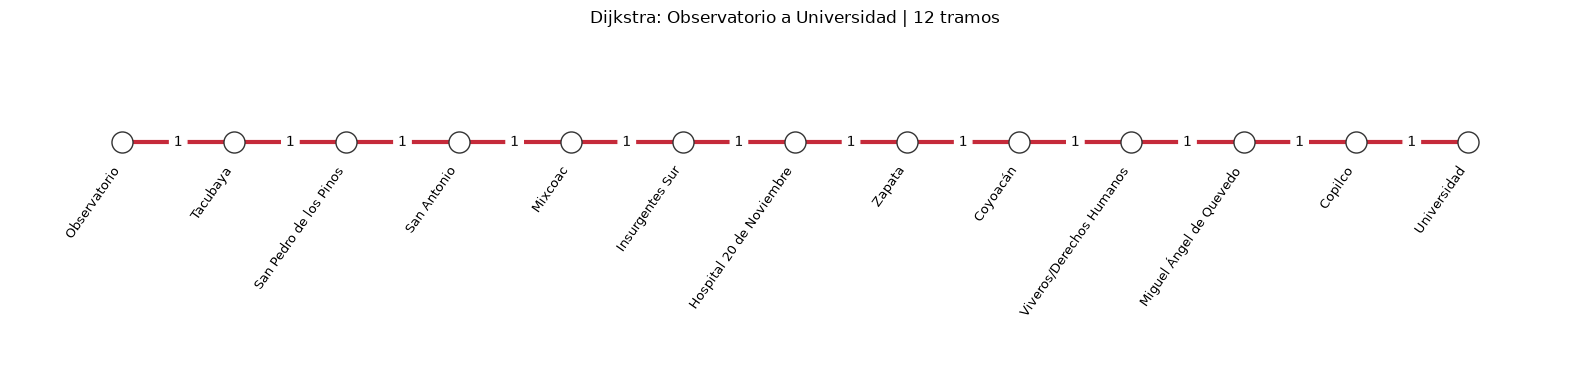

In [8]:
H = G.subgraph(camino)
pos = {nodo: (i, 0) for i, nodo in enumerate(camino)}
fig, ax = plt.subplots(figsize=(16, 4))
nx.draw_networkx_nodes(H, pos, node_color='white', edgecolors='#333333', node_size=230, ax=ax)
nx.draw_networkx_edges(H, pos, edge_color='#cccccc', width=2, ax=ax)
nx.draw_networkx_edges(H, pos, edgelist=list(zip(camino, camino[1:])),
                       edge_color='#c52a3a', width=3, ax=ax)
nx.draw_networkx_edge_labels(H, pos, edge_labels=nx.get_edge_attributes(H, 'weight'), ax=ax)
for nodo, (x, y) in pos.items():
    ax.annotate(nodo, (x, y), xytext=(0, -16), textcoords='offset points',
                rotation=55, ha='right', va='top', fontsize=9)
ax.set_title(f'Dijkstra: {origen} a {destino} | {costo} tramos')
ax.set_ylim(-1.5, .7)
ax.set_xlim(-1, len(camino))
ax.axis('off')
plt.tight_layout()
plt.show()

## 9. Conclusión

La matriz permite consultar conexiones y comprobar propiedades como simetría y grado. La lista de adyacencia permite explorar la red sin revisar todas las entradas de la matriz. Dijkstra obtiene un camino mínimo de Observatorio a Universidad de **12 tramos**, coincidente con NetworkX.

Como todos los pesos del Metro valen 1, BFS también obtiene el mínimo y es más eficiente para este caso. Dijkstra permite conservar el procedimiento si después se incorporan costos no negativos distintos por tramo.

## Referencias

- Material de clase: `intro_python_networkx(1).ipynb` y `dijkstra_corregido.ipynb`, compartidos por el profesor.
- [STC Metro: la red](https://www.metro.cdmx.gob.mx/la-red).
- [NetworkX: documentación](https://networkx.org/documentation/stable/).